# Chapter 6 — Inverse kinematics
**L4: analytic branches, numerical steps, pose errors, damping, and null-space motion.**

**Run from top to bottom.** Install the repository's `requirements-kinematics.txt` in your notebook environment, then select **Run All Cells**. No robot assets need downloading. Angles are in radians, lengths in metres, and twists are ordered $(v,\omega)$. All computations run locally; no robot commands are issued.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pinocchio as pin
from scipy.linalg import expm

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Pinocchio', pin.__version__, '| NumPy', np.__version__)
def position(q):
    q1, q2 = q
    return np.array([np.cos(q1) + np.cos(q1+q2),
                     np.sin(q1) + np.sin(q1+q2)])

def jacobian(q):
    q1, q2 = q
    return np.array([[-np.sin(q1)-np.sin(q1+q2), -np.sin(q1+q2)],
                     [ np.cos(q1)+np.cos(q1+q2),  np.cos(q1+q2)]])

def arm_points(q):
    elbow = np.array([np.cos(q[0]), np.sin(q[0])])
    return np.vstack(([0., 0.], elbow, position(q)))

def draw_arm(ax, q, label=None, **kwargs):
    xy = arm_points(q)
    ax.plot(xy[:, 0], xy[:, 1], 'o-', label=label, **kwargs)
    ax.set(xlabel='World x (m)', ylabel='World y (m)', aspect='equal')


Pinocchio 3.9.0 | NumPy 2.3.5


## 1. One target, two elbow branches
Solve the position task first, then inspect orientation. For $p_d=(1,1)$, the two branches have different tool orientations. The equal-link target $p_d=0$ is degenerate: $q_2=\pi$ and $q_1$ is arbitrary.


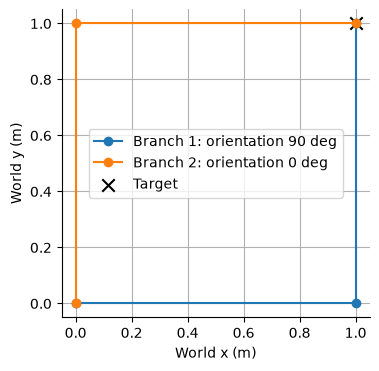

In [2]:
def analytic_ik(target):
    r2 = np.dot(target, target)
    if r2 < 1e-14:
        raise ValueError('At the origin there is a family: q2=pi and arbitrary q1.')
    c2 = (r2-2)/2
    if abs(c2) > 1+1e-12:
        return []
    c2 = np.clip(c2, -1, 1)
    solutions = []
    for sign in (1, -1):
        s2 = sign*np.sqrt(max(0., 1-c2*c2))
        solutions.append(np.array([np.arctan2(target[1],target[0])-np.arctan2(s2,1+c2),
                                   np.arctan2(s2,c2)]))
    return solutions

target = np.array([1.,1.])
solutions = analytic_ik(target)
fig, ax = plt.subplots()
for k, q in enumerate(solutions):
    np.testing.assert_allclose(position(q), target, atol=1e-12)
    draw_arm(ax, q, label=f'Branch {k+1}: orientation {np.degrees(q.sum()):.0f} deg')
ax.scatter(*target, marker='x', color='black', s=80, label='Target')
ax.legend(); plt.show()
assert analytic_ik(np.array([3.,0.])) == []


## 2. Reproduce the lecture's first Newton step
From `(0, pi/2)` toward `(1.1, 1.1)`, the step is `(0.1, -0.2)`. It solves the linear approximation; recompute the residual before taking another step.


In [3]:
q0 = np.array([0.,np.pi/2]); target = np.array([1.1,1.1])
step = np.linalg.solve(jacobian(q0), target-position(q0))
np.testing.assert_allclose(step, [.1,-.2], atol=1e-12)
print('First step:', step, '| new position:', position(q0+step))
print('Residual before/after:', np.linalg.norm(target-position(q0)), np.linalg.norm(target-position(q0+step)))


First step: [ 0.1 -0.2] | new position: [1.094838 1.094838]
Residual before/after: 0.14142135623730964 0.00730076165651172


## 3. Damped IK with a checked outcome
Solve $\Delta q=J^T(JJ^T+\lambda^2I)^{-1}(p_d-p)$, using a linear solver. Backtracking accepts only a step that decreases the actual residual. A small step is **not** automatically success. This is unconstrained IK: joint limits, contacts, and collision constraints enter L6.


target reached | iterations: 4 | q: [0.105787 1.359221]


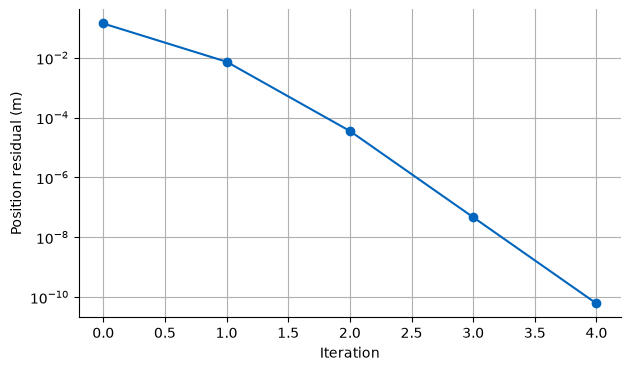

Straight-arm initial guess: stalled (try bending the initial guess)


In [4]:
def numerical_ik(target, initial, damping=.02, max_iterations=100):
    q = np.asarray(initial, dtype=float).copy(); history = []
    for iteration in range(max_iterations):
        error = target-position(q); error_norm = np.linalg.norm(error)
        history.append(error_norm)
        if error_norm < 1e-8: return q, 'target reached', history
        J = jacobian(q)
        step = J.T @ np.linalg.solve(J @ J.T + damping**2*np.eye(2), error)
        alpha = 1.
        while alpha >= 1/1024:
            candidate = q+alpha*step
            if np.linalg.norm(target-position(candidate)) < error_norm:
                q = candidate; break
            alpha *= .5
        else: return q, 'stalled', history
    return q, 'iteration limit', history

qsol, outcome, history = numerical_ik(target, q0)
assert outcome == 'target reached', outcome
np.testing.assert_allclose(position(qsol), target, atol=1e-8)
print(outcome, '| iterations:', len(history)-1, '| q:', qsol)
fig, ax = plt.subplots()
ax.semilogy(history, 'o-', color='#0065BD')
ax.set(xlabel='Iteration', ylabel='Position residual (m)'); plt.show()
# A straight arm cannot move radially at first order, even toward a reachable target.
_, stalled, _ = numerical_ik(np.array([1.8,0.]), np.zeros(2))
assert stalled == 'stalled'
print('Straight-arm initial guess:', stalled, '(try bending the initial guess)')


## 4. A full pose residual and its derivative
For this independent example use Pinocchio's built-in 6-joint sample arm. Choose a reachable target by forward kinematics, then solve from a different initial guess. The end effector here is the **last joint frame**, explicitly; it has no extra tool offset.

With $E=T^{-1}T_d$, use $e=\operatorname{Log}(E)$ and $J_e=-\mathrm{Jlog6}(E^{-1})J_b$. Check this derivative with finite differences before using it. Metres and radians are weighted explicitly via the characteristic length $\ell=1$ m.


Pose IK: target reached | final position/orientation errors: [np.float64(2.0133969737135873e-13), np.float64(2.5391255071211324e-14)]


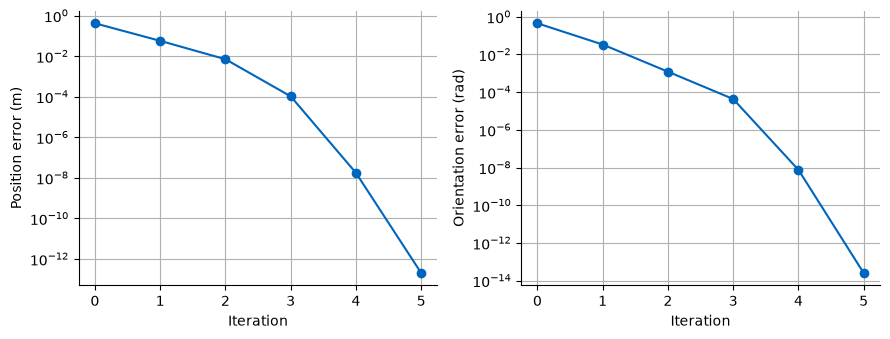

In [5]:
arm = pin.buildSampleModelManipulator()
work = arm.createData(); jid = arm.njoints-1
q_target = np.array([.2, -.5, .4, .7, -.3, .2])
pin.forwardKinematics(arm, work, q_target)
desired = work.oMi[jid].copy()

def pose_residual(q):
    pin.forwardKinematics(arm, work, q)
    E = work.oMi[jid].actInv(desired)
    return pin.log6(E).vector.copy(), E

def pose_linearization(q):
    e, E = pose_residual(q)
    Jb = pin.computeJointJacobian(arm, work, q, jid)
    return e, -pin.Jlog6(E.inverse()) @ Jb

qstart = q_target + np.array([.15,-.12,.1,-.1,.12,-.15])
direction = np.array([.2,.1,-.3,.2,-.1,.1]); eps = 1e-6
e, Je = pose_linearization(qstart)
fd = (pose_residual(pin.integrate(arm,qstart,eps*direction))[0]
      - pose_residual(pin.integrate(arm,qstart,-eps*direction))[0])/(2*eps)
np.testing.assert_allclose(fd, Je @ direction, atol=1e-8)

length_scale = 1.  # metres; converts the rotational residual to a comparable scale
W = np.diag([1.,1.,1.,length_scale,length_scale,length_scale])
q = qstart.copy(); pose_history = []; outcome = 'iteration limit'
for iteration in range(100):
    e, Je = pose_linearization(q)
    current = work.oMi[jid].copy()
    pos_error = np.linalg.norm(current.translation-desired.translation)
    rot_error = np.linalg.norm(e[3:])
    pose_history.append([pos_error, rot_error])
    if pos_error < 1e-8 and rot_error < 1e-8:
        outcome = 'target reached'; break
    A, b = W @ Je, W @ e
    step = -A.T @ np.linalg.solve(A @ A.T + .001**2*np.eye(6), b)
    alpha = 1.
    while alpha >= 1/1024:
        candidate = pin.integrate(arm, q, alpha*step)
        if np.linalg.norm(W @ pose_residual(candidate)[0]) < np.linalg.norm(b):
            q = candidate; break
        alpha *= .5
    else:
        outcome = 'stalled'; break
assert outcome == 'target reached', outcome
print('Pose IK:', outcome, '| final position/orientation errors:', pose_history[-1])
fig, axes = plt.subplots(1,2,figsize=(9,3.5))
for j, label in enumerate(['Position error (m)','Orientation error (rad)']):
    axes[j].semilogy(np.array(pose_history)[:,j], 'o-', color='#0065BD')
    axes[j].set(xlabel='Iteration', ylabel=label)
plt.tight_layout(); plt.show()


## 5. Null-space motion leaves the primary task unchanged
For two parallel sliders, $x=q_1+q_2$, $J=[1\;1]$, and $N=I-J^\dagger J$. The primary command is the minimum-norm solution; the secondary part redistributes extension.


In [6]:
J = np.array([[1.,1.]])
Jplus = np.linalg.pinv(J); N = np.eye(2)-Jplus @ J
Z = np.array([[1.],[-1.]])/np.sqrt(2)
np.testing.assert_allclose(J @ N, 0., atol=1e-12)
np.testing.assert_allclose(N @ N, N, atol=1e-12)
np.testing.assert_allclose(N, Z @ Z.T, atol=1e-12)
for eta in (-1., 0., 1.):
    rates = Jplus[:,0] + eta*np.array([1.,-1.])
    np.testing.assert_allclose(J @ rates, [1.], atol=1e-12)
    print('eta =',eta,'| joint rates =',rates,'| task rate =',J @ rates)


eta = -1.0 | joint rates = [-0.5  1.5] | task rate = [1.]
eta = 0.0 | joint rates = [0.5 0.5] | task rate = [1.]
eta = 1.0 | joint rates = [ 1.5 -0.5] | task rate = [1.]


## Try it
Change the planar target and initial guess. Compare reachable, unreachable, and singular starting cases. In pose IK, remove `Jlog6` temporarily and compare the derivative check; it is the finite-error residual derivative, not just a convention change.

Reference: [Pinocchio inverse-kinematics example and logarithm derivative](https://gepettoweb.laas.fr/doc/stack-of-tasks/pinocchio/devel/doxygen-html/md_doc_2b-examples_2d-inverse-kinematics.html). The examples here use the course's linear-first ordering. Constrained QP-based IK is reserved for L6.
